# Regression Lab: Regularization, SVM Regression and Logistic Regression

## Part A: Ridge and Lasso Regularization

In [1]:
import numpy as np
import pandas as pd
import random
import math
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.style.use('ggplot')
from matplotlib.pylab import rcParams
rcParams['figure.figsize'] = 10, 8

from sklearn import metrics
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
import numpy as np

import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
import sklearn.metrics as metrics

## Motivation behind regularization

Most, if not all real world data is noisy, i.e. there are outliers in the data which throw the model off during training. Let's look at a noisy sine wave as an example. We'll try to fit polynomials of various degree to the curve.

In [2]:
np.random.seed(10)

x = np.array([i*np.pi/180 for i in range(60,300,4)]).reshape((-1,1))
y = np.sin(x) + np.random.normal(0,0.15,x.shape)

In [3]:
def poly_regression(x, y, deg, show=True):

    poly = PolynomialFeatures(degree=deg)
    x_ = poly.fit_transform(x)

    m1 = LinearRegression()
    m1.fit(x_, y)
    y_pred = m1.predict(x_)

    if show:
        plt.figure(figsize=(10, 6))
        plt.plot(x, y_pred, color="red")
        plt.scatter(x, y, color="blue")
        plt.title(f"Polynomial Regression (degree={deg})")
        plt.legend(["Predicted polynomial", "Actual data"])
        plt.show()

        print("Coefficients obtained:")
        print(m1.coef_)

    return y_pred

In [4]:
import matplotlib.pyplot as plt

For now, let's not think about how we obtain these coefficients. We'll look into how they are obtained in a later module.

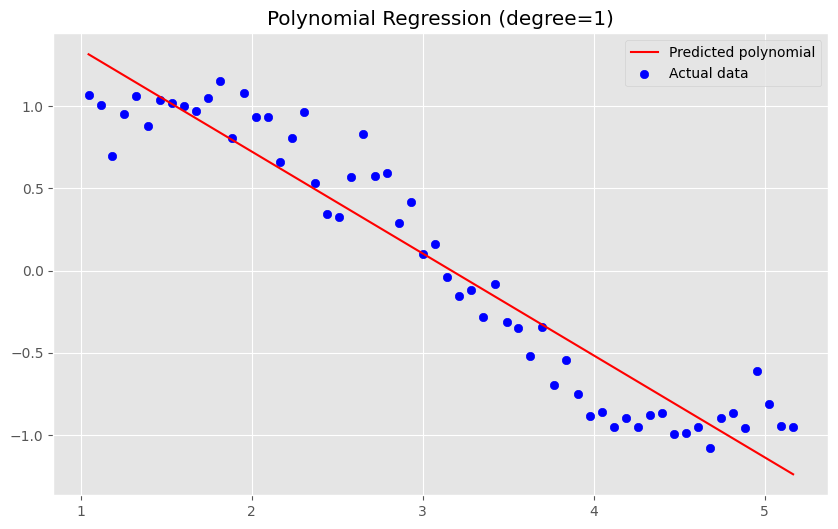

Coefficients obtained:
[[ 0.         -0.61957457]]


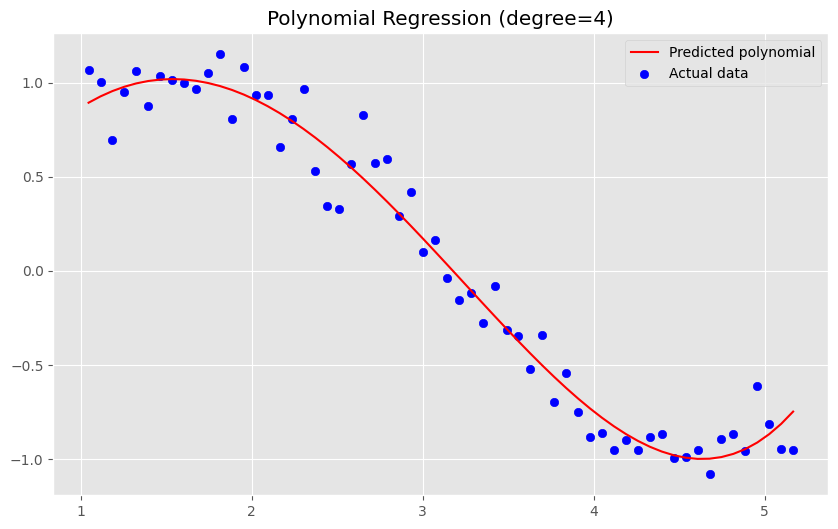

Coefficients obtained:
[[ 0.          1.68692165 -0.53175186 -0.03567846  0.01391921]]


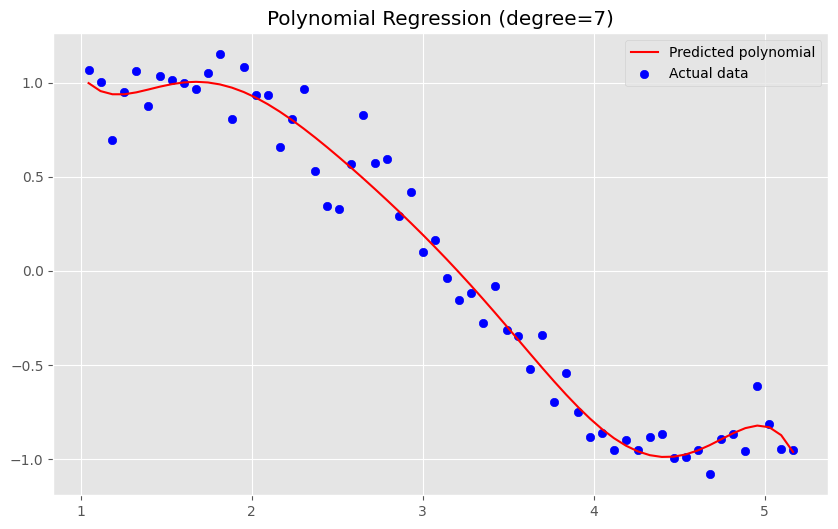

Coefficients obtained:
[[ 0.00000000e+00 -5.59523300e+01  6.89561793e+01 -4.46319058e+01
   1.65148424e+01 -3.52813549e+00  4.04509832e-01 -1.92268762e-02]]


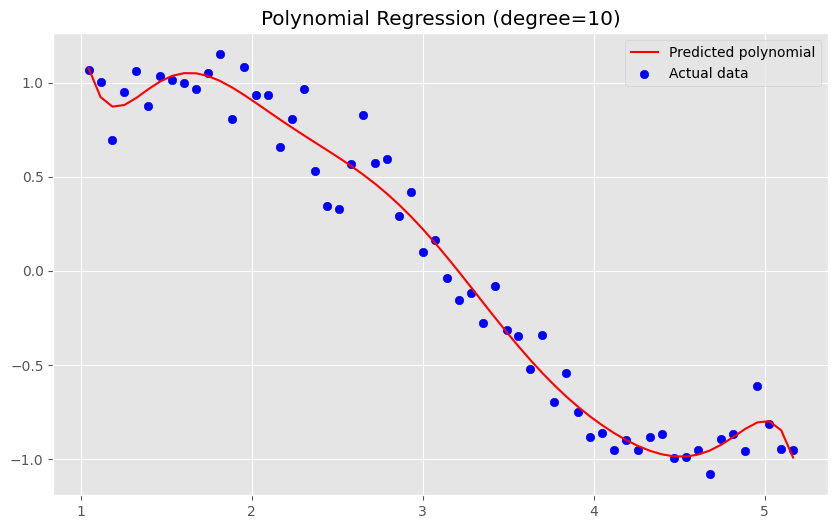

Coefficients obtained:
[[ 0.00000000e+00 -4.86125436e+02  7.26133286e+02 -5.95881204e+02
   2.93255837e+02 -8.74564585e+01  1.45461928e+01 -8.06079171e-01
  -1.38203819e-01  2.62230806e-02 -1.32095456e-03]]


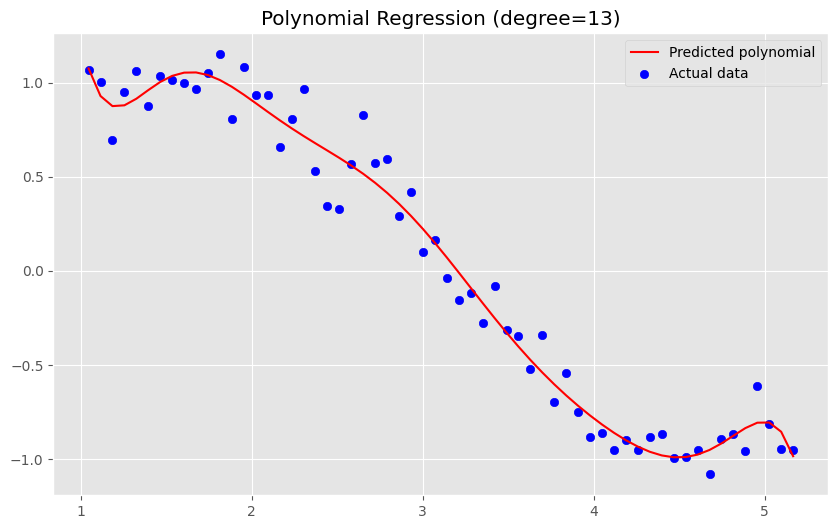

Coefficients obtained:
[[ 0.00000000e+00 -1.20901775e+02  5.00736786e+01  7.27324131e+01
  -5.64600592e+01 -4.13474096e+01  7.88655828e+01 -5.21574464e+01
   1.99430568e+01 -4.87943643e+00  7.78676260e-01 -7.87346339e-02
   4.59351098e-03 -1.18076316e-04]]


In [5]:
for deg in range(1, 14, 3):
    y_pred = poly_regression(x, y, deg)

The higher degree polynomials **overfit** the training data, by trying to capture noise in it. Though the model may do well on this set, if we try to fit the learnt curve to another noisy sine wave, it would result in a lower accuracy. Luckily, there's a way around this.

**Q:** What trend do you observe with respect to the coefficient values as degree grows?

\

**A:** The magnitudes of the coefficients go up drastically with degree!

\

Now, why does that happen? Intuitively, we can think about what the polynomial is trying to fit here. In the above example, the polynomial is trying to fit to a noisy sine wave. To approximate the large oscillations we see, the coefficients need to have large magnitudes. We can also see that this only happens with higher degree polynomials, since lower degree polynomials cannot even approximate these oscillations.

## Ridge Regression

Ridge regression works by adding a term to the loss function which is proportional to the sum of the squared coefficients of the model.

$L_r = \sum_{i=1}^{N} (y - y_p) ^2 + \alpha |w|^2$,

where $\sum_{i=1}^{N} (y - y_p) ^2$ is the typical mean-squared error loss and $\alpha |w|^2$ is the regularization term, $w$ being the coefficient of the term. We can see that it penalizes the squared value of the coefficients.

In [6]:
def ridge_regression(x,y,deg,alpha):

  poly = PolynomialFeatures(degree=deg)
  x_ = poly.fit_transform(x)

  r = Ridge(alpha)
  r.fit(x_,y)

  y_pred_ridge = r.predict(x_)

  plt.title("Ridge Regressed polynomial deg={}, alpha={}".format(deg,alpha))
  plt.scatter(x,y,color="blue")
  plt.plot(x,y_pred_ridge,color="red")
  plt.legend(["actual data","predicted data"])
  plt.show()

  print("\n Coefficients obtained\n")
  print(r.coef_)
  print("\n")

## Lasso Regression

Lasso regression is similar to ridge regression, except it penalizes the absolute value of the weights.

$L_l = \sum_{i=1}^{N} (y - y_p) ^2 + \alpha |w|$

In [7]:
def lasso_regression(x,y,deg,alpha):

  poly = PolynomialFeatures(degree=deg)
  x_ = poly.fit_transform(x)

  l = Lasso(alpha)
  l.fit(x_,y)

  y_pred_lasso = l.predict(x_)

  plt.title("Lasso Regressed polynomial deg={}, alpha={}".format(deg,alpha))
  plt.scatter(x,y,color="blue")
  plt.show()

  print("\n Coefficients obtained\n")
  print(l.coef_)
  print("\n")

### Feature selection

Sometimes, data may contain features that are not relevant to the model; they do not contribute to the model's predictions. Naturally, we would want to get rid of such features in our data. **Feature selection** is a process by which we understand which features are actually relevant to the model and remove the unrelated features from our data.

The advantage of lasso regularization over ridge regularization is that it does a better job of feature selection. In ridge regression, the coefficient can approach zero, but never truly reaches zero. Hence, the model cannot perform feature selection.

In lasso regression, since we are penalizing the absolute value of the coefficient, the feature can have a zero coefficient, which is the same as feature selection. In the above example, we can clearly see the feature selection process in action, with higher degree polynomials have zero-valued coefficients for some of the terms.

## Applying regularization to the crime dataset

In [8]:
src = 'http://archive.ics.uci.edu/ml/machine-learning-databases/communities/communities.data'
crime = pd.read_csv(src, header=None, na_values=['?'])

crime.head()

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [9]:
def lin_regression(x,y,show=True):

  # learning the coefficient and intercept

  x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2)

  m1 = LinearRegression()
  m1.fit(x_train,y_train)

  y_pred = m1.predict(x_test)
  metrics.mean_squared_error(y_pred,y_test)

  # plotting data and predictions

  if show:

    print("The coefficients are: \n {} \n\n The intercept is: {}\n".format(m1.coef_,m1.intercept_))
    print("The RMSE for linear regression is: {}".format(math.sqrt(metrics.mean_squared_error(y_pred,y_test))))

In [10]:
# Remove identifier columns and target column
x_crime = crime.drop(columns=[0, 1, 2, 3, 4, 127])

# Target variable
y_crime = crime[127]

# Convert remaining features to numeric
x_crime = x_crime.apply(pd.to_numeric, errors='coerce')

# Replace missing values with column median
x_crime = x_crime.fillna(x_crime.median())

In [11]:
lin_regression(x_crime, y_crime)

The coefficients are: 
 [ 2.62189350e-01 -5.74943620e-02  1.21451878e-01 -1.44551700e-01
 -5.06896299e-02  1.15923540e-01  3.35495886e-02 -3.13848308e-01
 -2.24658298e-02 -4.50828117e-02 -4.09478957e-01  5.94607551e-02
 -3.11598556e-01 -1.40804858e-01  6.26475282e-02 -1.81274800e-01
  2.31072665e-01 -3.42828277e-02 -8.79025353e-02  4.38660978e-01
  3.01148935e-02 -3.30709240e-01 -3.49813567e-02 -1.84772883e-02
  2.70178344e-02  3.92498383e-02  2.94942077e-02  2.64060211e-01
 -2.02351410e-01 -9.05322518e-02  6.90550353e-02  8.54866519e-02
  2.53339123e-02  2.55158589e-01 -4.53810570e-02 -2.89906751e-02
  5.85006272e-02  1.32330637e-01  5.21282014e-01  2.33891388e-01
  1.37919933e-01 -6.30317933e-01 -5.47275833e-03 -2.07115500e-01
 -1.75017245e-01 -6.12872181e-02  2.65001821e-02  1.86846290e-02
 -1.56463221e-01 -1.98844110e-01  1.06191780e-01 -2.00140452e-01
  1.14060810e-03  4.03836620e-02 -1.22870746e-03 -4.93634233e-02
 -3.79321543e-02 -8.28760780e-02  9.97784708e-02  1.23178426e-02
 

In [12]:
x_train,x_test,y_train,y_test = train_test_split(x_crime,y_crime,test_size=0.3)

In [13]:
l = Lasso(alpha=0.002)
l.fit(x_train,y_train)
y_pred_lasso = l.predict(x_test)

print("The coefficients are: \n {}".format(l.coef_))
print("The RMSE for lasso regression is: {}".format(math.sqrt(metrics.mean_squared_error(y_pred_lasso,y_test))))

The coefficients are: 
 [ 0.         -0.          0.07548453 -0.13340209  0.          0.
 -0.         -0.         -0.          0.          0.          0.03222945
 -0.         -0.          0.         -0.          0.          0.
 -0.         -0.          0.          0.         -0.         -0.
  0.          0.          0.          0.          0.          0.
  0.         -0.          0.         -0.         -0.         -0.
 -0.         -0.          0.11422596 -0.          0.          0.
  0.         -0.         -0.2570344  -0.         -0.         -0.
 -0.02721596  0.          0.18208815  0.          0.          0.
  0.          0.          0.          0.          0.          0.
 -0.          0.          0.          0.          0.         -0.
  0.         -0.          0.09973808  0.         -0.          0.06699947
 -0.03870963 -0.          0.02424044 -0.          0.          0.
  0.          0.          0.          0.         -0.          0.
  0.          0.          0.          0.         -

## Part B: SVM Regression

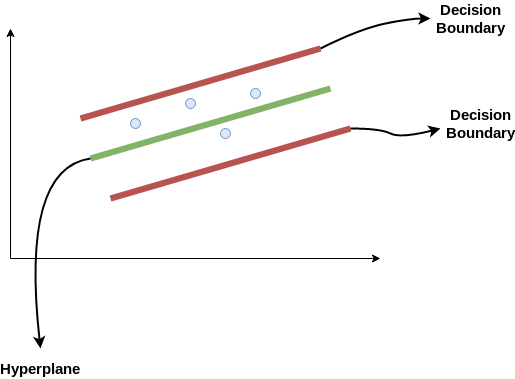

We know that the SVM algorithm works by finding a dividing hyperplane between the two classes in some feature space. How do we apply that concept to the task of regression?

The key insight is that we can define a parameter $ϵ$ which defines a "tube" around the hyperplane (in the diagram, the green line is the hyperplane and the two red lines determine the tube around it. Each red line is $ϵ$ units away from the hyperplane. We then define a "slack" term $ξ$ which measures the distance between the decision boundary (red line) and outliers (points outside the tube). In the code below, the variable `C` represents the slack term.

We can thus define an optimization problem of minimizing the $ξ$ value while trying to fit as many points in the tube as possible.

In [14]:
import numpy as np

np.random.seed(10)

X = np.linspace(-5, 5, 100).reshape(-1, 1)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, 100)

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR

model1 = LinearRegression()
model1.fit(X, y)

epsilon = 0.1
model2 = SVR(kernel='rbf', C=100, epsilon=epsilon)
model2.fit(X, y)

SVR(C=100)

In [16]:
x_range = np.linspace(X.min(), X.max(), 100)

y_lr = model1.predict(x_range.reshape(-1, 1))
y_svr = model2.predict(x_range.reshape(-1, 1))

In [17]:
import plotly.express as px
import plotly.graph_objects as go

fig = px.scatter(
    x=X.flatten(),
    y=y,
    opacity=0.8,
    color_discrete_sequence=['black']
)

fig.add_trace(go.Scatter(
    x=x_range, y=y_lr,
    name='Linear Regression',
    line=dict(color='limegreen')
))

fig.add_trace(go.Scatter(
    x=x_range, y=y_svr,
    name='Support Vector Regression',
    line=dict(color='red')
))

fig.add_trace(go.Scatter(
    x=x_range, y=y_svr + epsilon,
    name='+epsilon',
    line=dict(color='red', dash='dot')
))

fig.add_trace(go.Scatter(
    x=x_range, y=y_svr - epsilon,
    name='-epsilon',
    line=dict(color='red', dash='dot')
))

fig.update_layout(
    plot_bgcolor='white',
    title='Linear Regression vs Support Vector Regression',
    xaxis_title='X',
    yaxis_title='Y'
)

fig.update_xaxes(
    showgrid=True, gridwidth=1, gridcolor='lightgrey',
    zeroline=True, zerolinewidth=1, zerolinecolor='lightgrey',
    showline=True, linewidth=1, linecolor='black'
)

fig.update_yaxes(
    showgrid=True, gridwidth=1, gridcolor='lightgrey',
    zeroline=True, zerolinewidth=1, zerolinecolor='lightgrey',
    showline=True, linewidth=1, linecolor='black'
)

fig.update_traces(marker=dict(size=3))

fig.show()

## Part C: Logistic Regression

Just as we have linear and polynomial regression for predicting numerical values, we have another type of regression for predicting class labels of data, namely **logistic regression**.

The reason its called logistic regression is because it makes use of the logistic function to generate output values. The logistic function is defined as:

$g(z) = \frac{1}{1 + e^{-z}}$

\

The reason we use the logistic function is because its range is bounded between 0 and 1. Anything else comes to mind when talking about values between 0 and 1? Probabilities! And we saw in lab 2 how deeply related probability and classification are.

<img src="https://drive.google.com/uc?export=view&id=1db86qd4W_4erTMC9no5P4ylWze6c2j7V" width="500" height="350" align="middle"/>

## Why use logistic function? Why not use linear regression?

Let's see why we can't use linear regression for classification tasks with the help of an example.

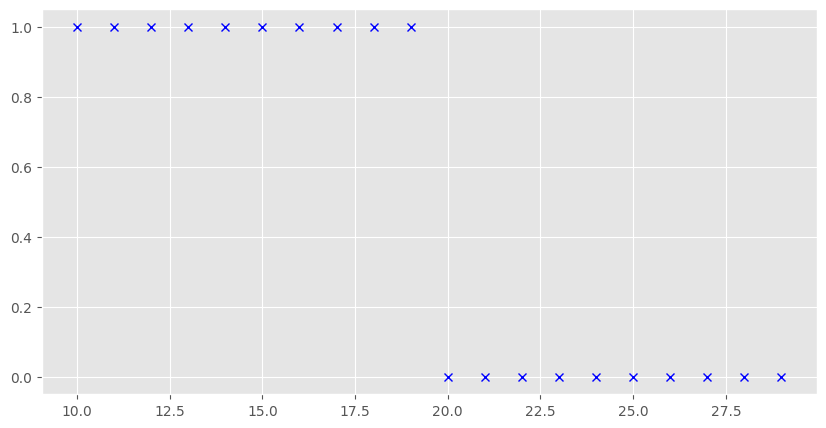

In [18]:
x = np.array([i for i in range(10,30)])
y = np.concatenate([np.ones(10), np.zeros(10)])

fig = plt.figure(figsize=(10,5))
_ = plt.plot(x, y, 'xb')

Suppose we have some product, and we collected data on the relationship between the age of a customer, and whether they purchased the item or not. Customers aged between 10 and 19 made the purchase (purchased=1), whereas those customers above the age of 19 did not (purchased=0).

\

Now, let's try and fit linear regression and logistic regression models to this data, and test it.

In [19]:
def linear_regression(x,y):

  lin_regression = LinearRegression()
  lin_regression.fit(pd.DataFrame(x), y)

  lin_y_pred_1 = lin_regression.predict(pd.DataFrame(x))

  line_point_5 = x * 0 + .5

  fig = plt.figure(figsize=(10,5))
  xlabel = 'Age'
  ylabel = 'Purchased'
  plt.xlabel(xlabel)

  plt.legend(["Data Points","Linear Regression Model","Decision Boundary"])
  plt.show()

  return lin_regression

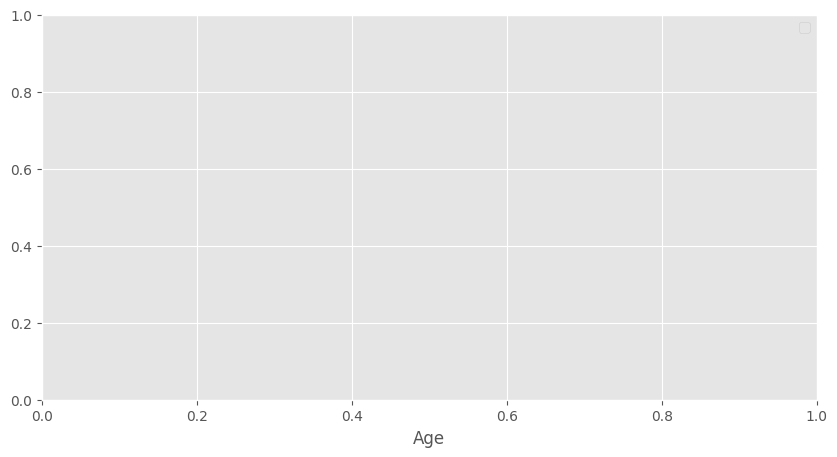

In [20]:
lin_regression = linear_regression(x,y)

The green line is called the decision boundary, which is basically the line that divides the two classes on the cartesian plane.

In [21]:
test_x = np.array([i for i in range(10,35,5)])
test_y_pred = lin_regression.predict(pd.DataFrame(test_x))
test_y_pred

array([ 1.21428571,  0.83834586,  0.46240602,  0.08646617, -0.28947368])

Since linear regression predictions are not probabilities, values greater than 0.5 are considered to belong to positive purchase class.

In [22]:
def logistic_regression(x,y):

    log_regression = LogisticRegression()

    log_regression.fit(pd.DataFrame(x), y)

    log_y_pred_1 = log_regression.predict(pd.DataFrame(x))

    xlabel = 'Age'
    ylabel = 'Purchased'

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    plt.grid(color='k', linestyle=':', linewidth=1)

    plt.plot(x, y, 'xb')
    plt.plot(x, log_y_pred_1, '-r')

    plt.legend(["Data Points","Logistic Regression Model"])
    plt.show()

    return log_regression

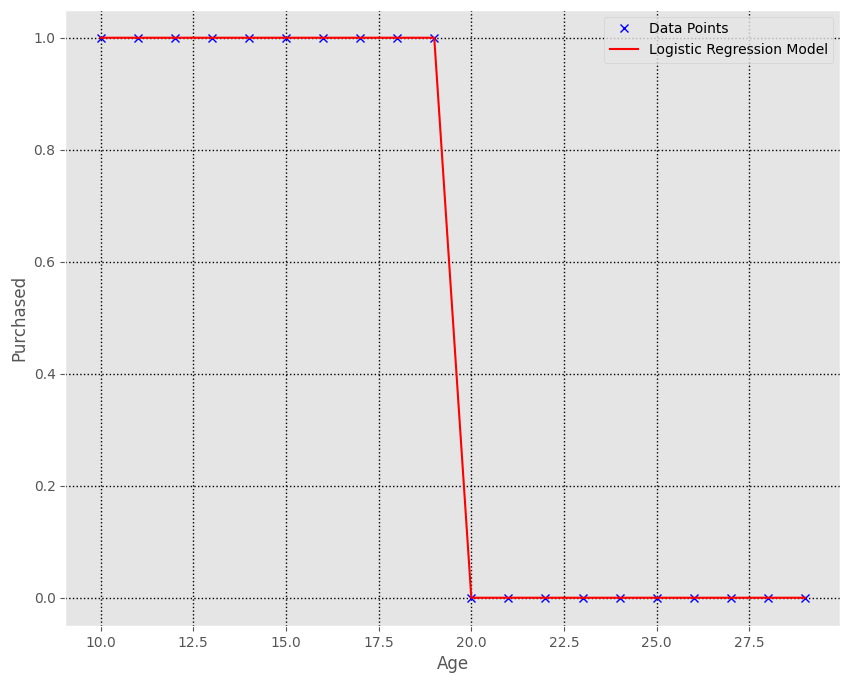

In [23]:
log_regression = logistic_regression(x,y)

**Q:** What do you observe from the two graphs? Hint: think in terms of the decision boundary....

**A:** According to the linear regression model, any age greater than 19 would belong to class 0 (no purchase), and any age less than or equal to 19 would belong to class 1 (purchase made). The logistic regression curve follows the same trend. We can think of the age 19 as a turning point of sorts.

Now, say we've collected more data the next day, and add the new data to the existing data we had from day 1. We find that customers aged between 60 and 70 did not make a purchase, which is aligned with our earlier data as well.

In [24]:
x = np.append(x, np.array([i for i in range(60,70)]))
y = np.append(y, np.zeros(10))

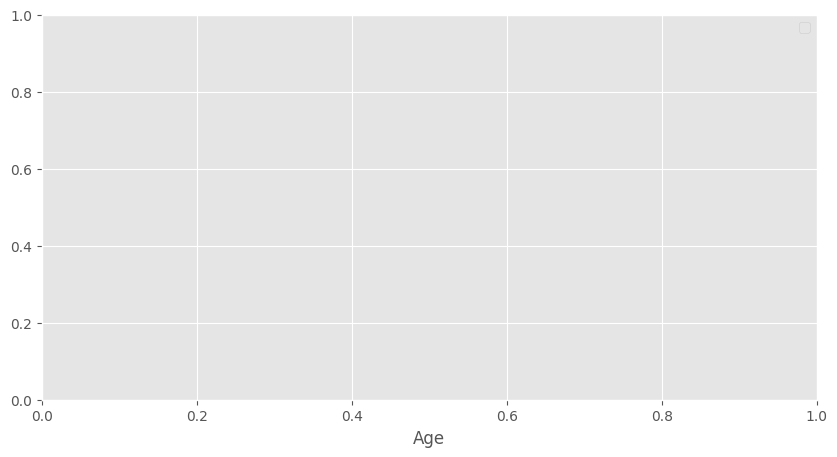

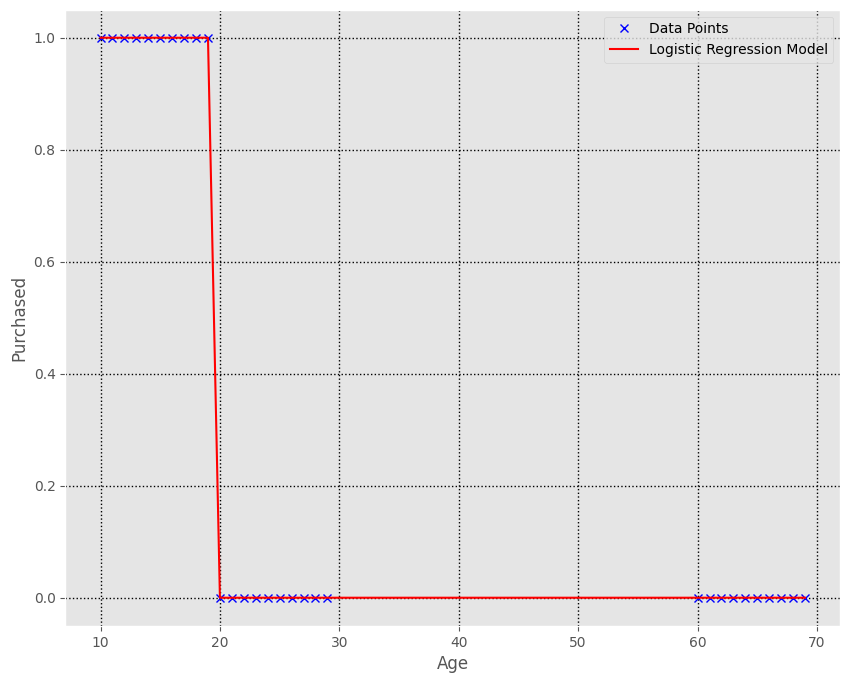

In [25]:
lin_regression = linear_regression(x,y)
log_regression = logistic_regression(x,y)

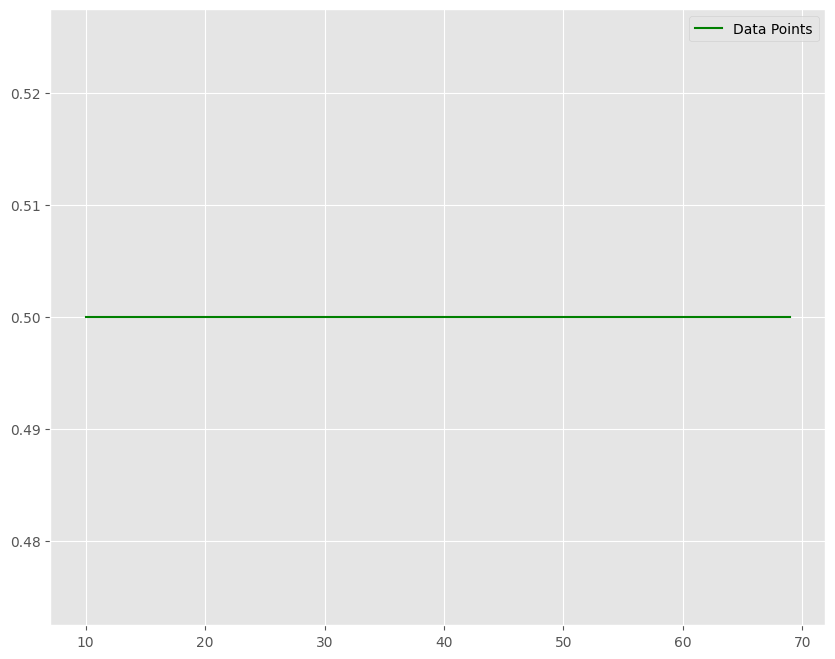

In [26]:
test_x = np.array([i for i in range(18,26)])

test_y_pred_lin = lin_regression.predict(pd.DataFrame(test_x))

line_point_5 = x * 0 + 0.5

plt.plot(x, line_point_5, '-g')
plt.legend(["Data Points", "Logistic Regression Model", "Decision Boundary"])
plt.show()


We can now see where linear regression fails. The model tries to fit as many points as it can. By doing so, the turning point which was earlier 19 has now increased to 23, which is clearly wrong for the values 20, 21 and 22, which can be seen from the predictions on the test data.

\

On the other hand, the logistic regression model predicts the classes correctly, and perfectly models the relationship between the data.

What we can conclude from these observations are that a probabilistic model is required for classification problems. Lab 2 covered the intuition behind MLE, cross-entropy and classification, and so now you should be able to appreaciate the motivation behind logistic regression.

## Applying logistic regression to MNIST digit Dataset

Let's see logistic regression in action with the MNIST digits dataset.

In [27]:
import seaborn as sns

In [28]:
from sklearn.datasets import load_digits

digits = load_digits()

In [29]:
x_train, x_test, y_train, y_test = train_test_split(
    digits.data,
    digits.target,
    test_size=0.2,
    random_state=0
)

log_reg = LogisticRegression()
log_reg = log_reg.fit(x_train, y_train)

In [30]:
# Accuracy

acc = log_reg.score(x_test,y_test)
print("Accuracy obtained on test set: {}".format(round(acc*100,3)))

Accuracy obtained on test set: 96.667


In [31]:
y_pred = log_reg.predict(x_test)

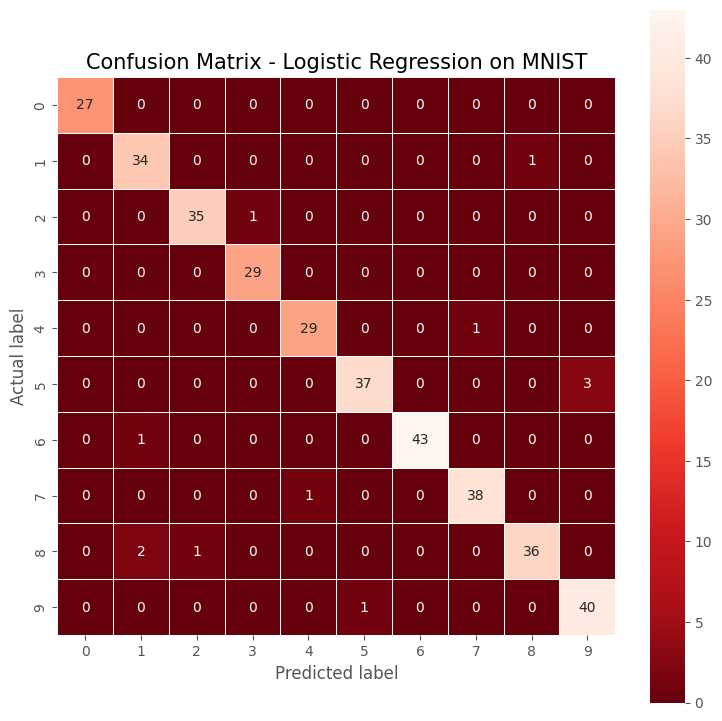

In [32]:
cm = metrics.confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9,9))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Reds_r')

plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title("Confusion Matrix - Logistic Regression on MNIST", size=15)
plt.show()

## Exercises

### Regularization:
1. Play with the values of alpha in both regularization techniques, and try to predict the outcomes.
2. Try the regularizations on different datasets to see the effect in various ways.

### SVM regression:
1. Play around with the value of `epsilon` and plot the different regression curves obtained.
2. Change `C` and analyze the different plots obtained.

### Logistic regression:
1. Run logistic regression on different datasets and assess the results.

alpha=1e-15  | Ridge RMSE=0.119, max |coef|=6.70e+04 | Lasso RMSE=0.127, non-zero coefs=13
alpha=0.0001 | Ridge RMSE=0.123, max |coef|=6.32e+00 | Lasso RMSE=0.127, non-zero coefs=12
alpha=0.01   | Ridge RMSE=0.125, max |coef|=2.33e-01 | Lasso RMSE=0.128, non-zero coefs=10
alpha=1      | Ridge RMSE=0.126, max |coef|=3.31e-02 | Lasso RMSE=0.132, non-zero coefs=8
alpha=10     | Ridge RMSE=0.126, max |coef|=8.03e-03 | Lasso RMSE=0.153, non-zero coefs=6
alpha=100    | Ridge RMSE=0.127, max |coef|=1.80e-03 | Lasso RMSE=0.187, non-zero coefs=6


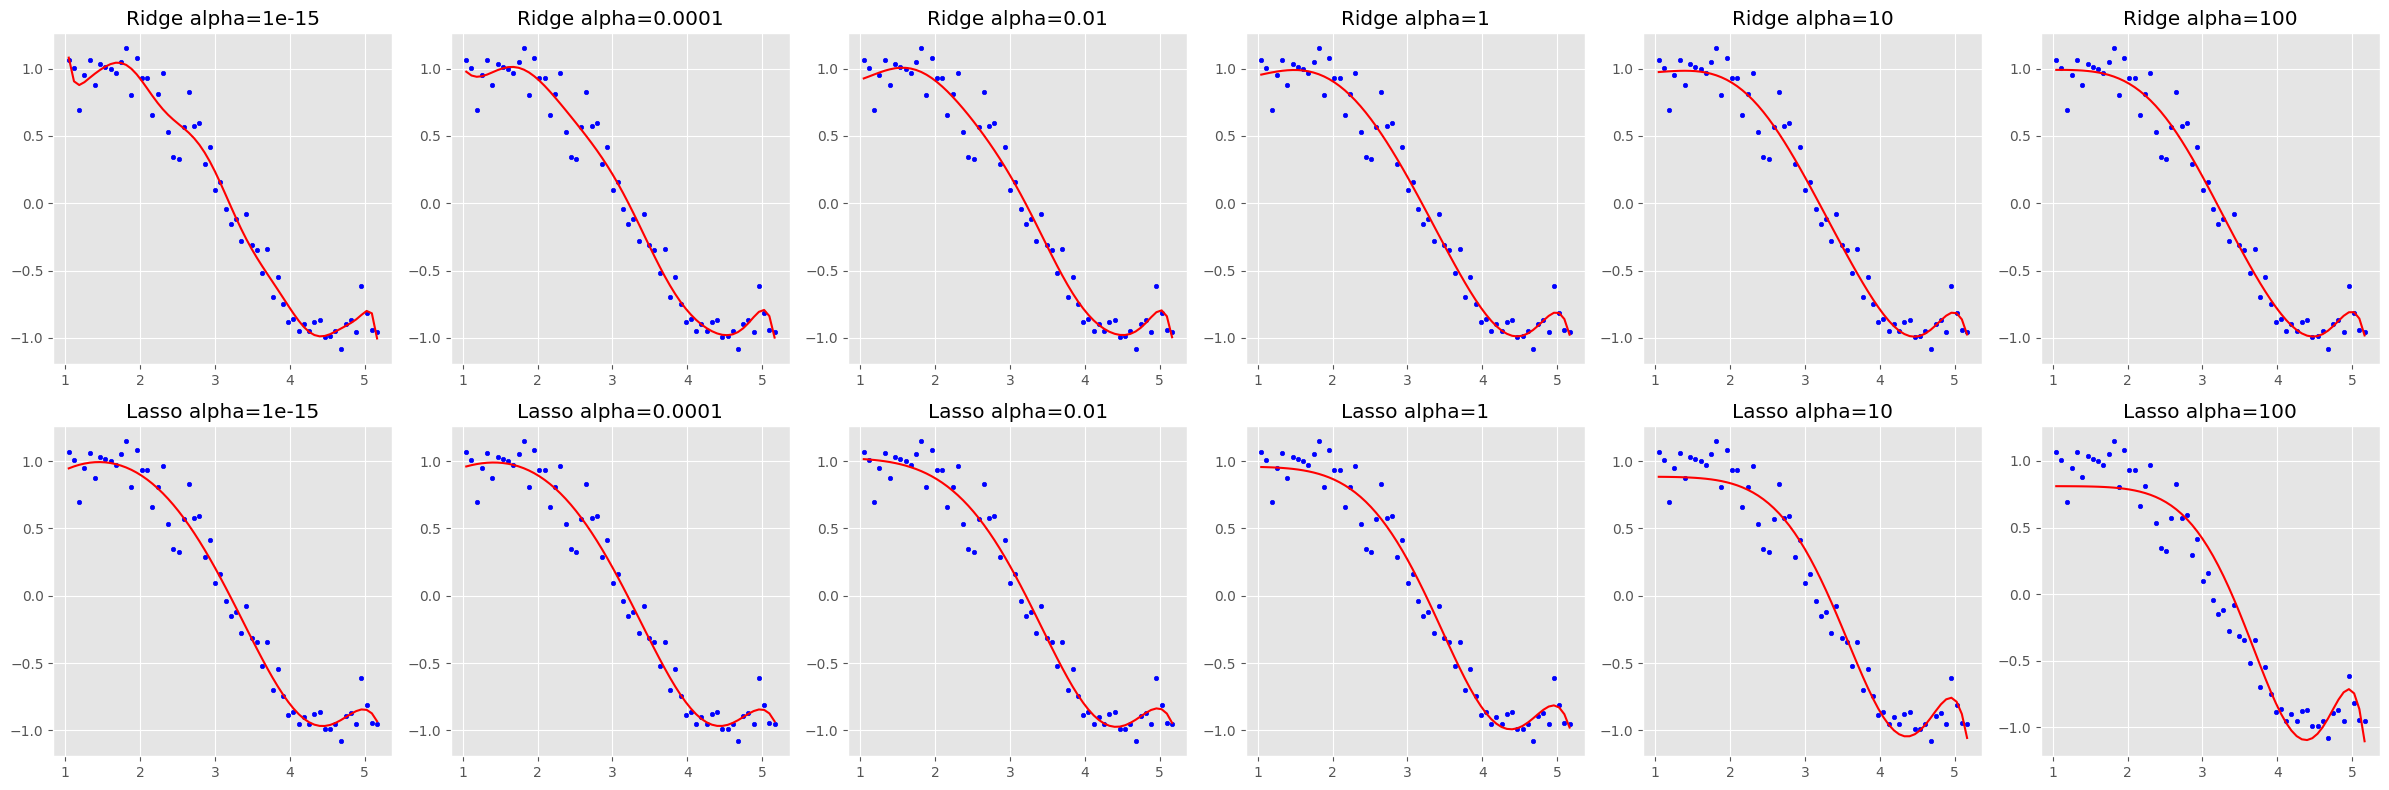

In [33]:
#Regularization:
#Play with the values of alpha in both regularization techniques, and try to predict the outcomes.

alphas = [1e-15, 1e-4, 1e-2, 1, 10, 100]

np.random.seed(10)
x = np.array([i*np.pi/180 for i in range(60,300,4)]).reshape((-1,1))
y = np.sin(x) + np.random.normal(0,0.15,x.shape)

poly = PolynomialFeatures(degree=13)
x_ = poly.fit_transform(x)

fig, axes = plt.subplots(2, len(alphas), figsize=(24, 8))
for i, a in enumerate(alphas):
    r = Ridge(alpha=a).fit(x_, y)
    l = Lasso(alpha=a, max_iter=100000).fit(x_, y)

    axes[0, i].scatter(x, y, s=10, color="blue")
    axes[0, i].plot(x, r.predict(x_), color="red")
    axes[0, i].set_title(f"Ridge alpha={a}")

    axes[1, i].scatter(x, y, s=10, color="blue")
    axes[1, i].plot(x, l.predict(x_), color="red")
    axes[1, i].set_title(f"Lasso alpha={a}")

    print(f"alpha={a:<6} | Ridge RMSE={math.sqrt(metrics.mean_squared_error(y, r.predict(x_))):.3f}, "
          f"max |coef|={np.abs(r.coef_).max():.2e} | "
          f"Lasso RMSE={math.sqrt(metrics.mean_squared_error(y, l.predict(x_))):.3f}, "
          f"non-zero coefs={np.sum(l.coef_ != 0)}")
plt.tight_layout()
plt.show()

Observations:

Prediction before running: a small alpha should behave like plain polynomial regression and overfit. A large alpha should shrink the weights so much that the model underfits. The results agree with this.
With alpha = 1e-15, ridge is effectively unregularised. The largest coefficient is about 67,000 and the curve bends to follow the noise. Training RMSE is lowest here (0.120), but this is the overfitting case.
In ridge, raising alpha shrinks every coefficient towards zero, but none of them reach exactly zero. The maximum coefficient falls from 6.7e4 to 1.8e-3, and the curve becomes smoother. Training RMSE only rises slightly (0.120 to 0.127), because the smoothed curve still follows the sine shape.
In lasso, coefficients become exactly zero. The count of non-zero coefficients drops from 13 to 6 as alpha grows, so lasso is doing feature selection by dropping higher-degree terms. Past alpha = 1 the curve flattens and RMSE rises quickly (0.187 at alpha = 100), which is underfitting.
For the same alpha, lasso is more aggressive than ridge. The L1 penalty pushes small weights all the way to zero, while the L2 penalty only scales them down.

Linear regression RMSE: 55.65
alpha=0.001: Ridge RMSE=55.68 | Lasso RMSE=55.68, non-zero=10/10
alpha=0.01: Ridge RMSE=55.75 | Lasso RMSE=55.88, non-zero=9/10
alpha=0.1: Ridge RMSE=55.23 | Lasso RMSE=55.90, non-zero=7/10
alpha=1: Ridge RMSE=56.91 | Lasso RMSE=59.51, non-zero=2/10
alpha=10: Ridge RMSE=66.37 | Lasso RMSE=71.42, non-zero=0/10


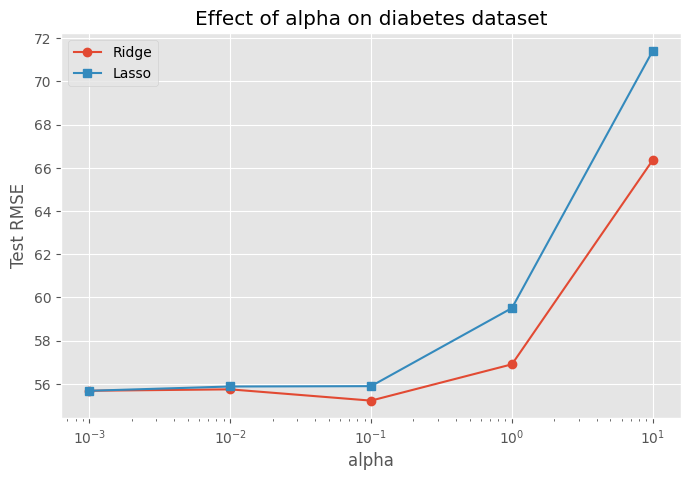

crime alpha=0.0001: Lasso RMSE=1.9106, non-zero=61 | Ridge(alpha=0.01) RMSE=1.9135
crime alpha=0.001: Lasso RMSE=1.8984, non-zero=58 | Ridge(alpha=0.1) RMSE=1.9122
crime alpha=0.01: Lasso RMSE=1.8989, non-zero=48 | Ridge(alpha=1.0) RMSE=1.9057
crime alpha=0.1: Lasso RMSE=1.9146, non-zero=39 | Ridge(alpha=10.0) RMSE=1.9005


In [34]:
#Exercise 2: regularization on a different dataset (diabetes)
from sklearn.datasets import load_diabetes

X_d, y_d = load_diabetes(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X_d, y_d, test_size=0.3, random_state=0)

lr = LinearRegression().fit(Xtr, ytr)
print("Linear regression RMSE:", round(math.sqrt(metrics.mean_squared_error(yte, lr.predict(Xte))), 2))

alphas = [0.001, 0.01, 0.1, 1, 10]
ridge_rmse, lasso_rmse, lasso_nz = [], [], []
for a in alphas:
    r = Ridge(alpha=a).fit(Xtr, ytr)
    l = Lasso(alpha=a).fit(Xtr, ytr)
    ridge_rmse.append(math.sqrt(metrics.mean_squared_error(yte, r.predict(Xte))))
    lasso_rmse.append(math.sqrt(metrics.mean_squared_error(yte, l.predict(Xte))))
    lasso_nz.append(np.sum(l.coef_ != 0))
    print(f"alpha={a}: Ridge RMSE={ridge_rmse[-1]:.2f} | Lasso RMSE={lasso_rmse[-1]:.2f}, non-zero={lasso_nz[-1]}/10")

plt.figure(figsize=(8,5))
plt.semilogx(alphas, ridge_rmse, 'o-', label="Ridge")
plt.semilogx(alphas, lasso_rmse, 's-', label="Lasso")
plt.xlabel("alpha"); plt.ylabel("Test RMSE"); plt.legend()
plt.title("Effect of alpha on diabetes dataset")
plt.show()

# Optional: same thing on the crime dataset already loaded above
for a in [0.0001, 0.001, 0.01, 0.1]:
    l = Lasso(alpha=a).fit(x_train, y_train)
    r = Ridge(alpha=a*100).fit(x_train, y_train)
    print(f"crime alpha={a}: Lasso RMSE={math.sqrt(metrics.mean_squared_error(y_test, l.predict(x_test))):.4f}, "
          f"non-zero={np.sum(l.coef_!=0)} | Ridge(alpha={a*100}) RMSE={math.sqrt(metrics.mean_squared_error(y_test, r.predict(x_test))):.4f}")

Observations:

The diabetes dataset has only 10 features, and linear regression does not overfit it badly. Regularization therefore gives only a small gain: ridge at alpha = 0.1 scores 55.23, against 55.65 for linear regression.
Lasso at alpha = 0.1 drops 3 of the 10 features and loses almost no accuracy. Those features add little to the prediction. At alpha = 1 only 2 features remain (BMI and s5), and RMSE is still close to the best value. Those two features carry most of the signal.
At alpha = 10, lasso sets every coefficient to zero and predicts only the mean, so RMSE jumps to 71.4. Ridge also degrades at this alpha, but more slowly.
On the crime dataset (122 features, many of them correlated), the effect is larger. Lasso keeps only a small subset of the features at a similar or lower RMSE than linear regression. Regularization matters most when there are many features relative to samples, or when features are collinear.

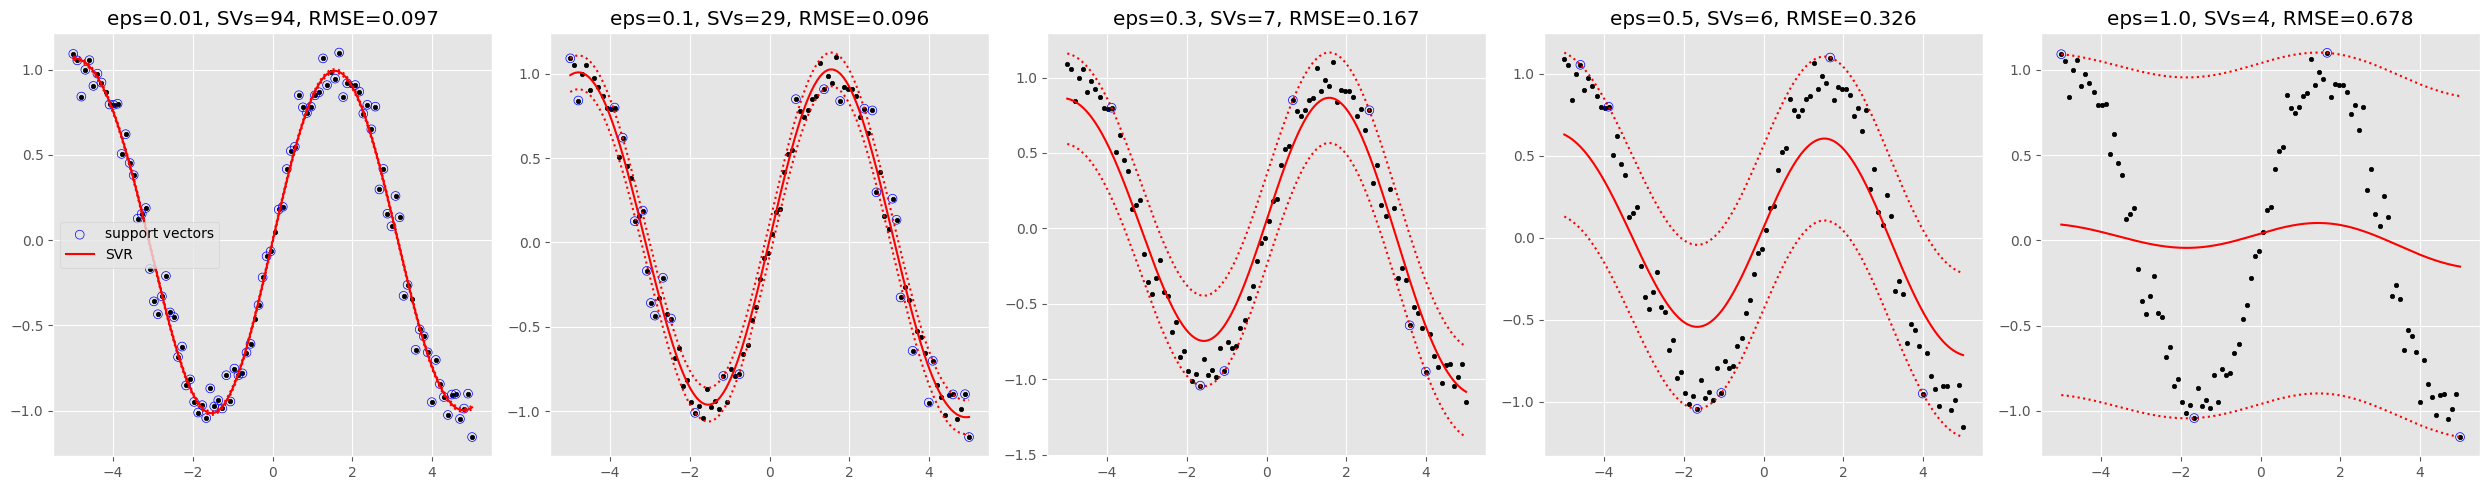

In [36]:
#SVM regression
#Exercise 1: varying epsilon
np.random.seed(10)
X = np.linspace(-5, 5, 100).reshape(-1, 1)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, 100)
x_range = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)

epsilons = [0.01, 0.1, 0.3, 0.5, 1.0]
fig, axes = plt.subplots(1, len(epsilons), figsize=(25, 5))
for ax, eps in zip(axes, epsilons):
    m = SVR(kernel='rbf', C=100, epsilon=eps).fit(X, y)
    y_hat = m.predict(x_range)
    ax.scatter(X, y, s=10, color='black')
    ax.scatter(X[m.support_], y[m.support_], s=40, facecolors='none', edgecolors='blue', label='support vectors')
    ax.plot(x_range, y_hat, 'r', label='SVR')
    ax.plot(x_range, y_hat + eps, 'r:', x_range, y_hat - eps, 'r:')
    rmse = math.sqrt(metrics.mean_squared_error(y, m.predict(X)))
    ax.set_title(f"eps={eps}, SVs={len(m.support_)}, RMSE={rmse:.3f}")
axes[0].legend()
plt.tight_layout()
plt.show()

Observations:

Epsilon sets the width of the tube. Points inside the tube add no loss, and only points on or outside its edge become support vectors.
A very small epsilon (0.01) makes almost every point (94 of 100) a support vector. The fit follows the noise closely and the model is less sparse.
At epsilon = 0.1, which roughly matches the noise level of 0.1, the curve follows the sine wave well with only 29 support vectors. This is the best setting of the five.
At epsilon = 0.3 and above, the tube is wider than the noise, so the model stops responding to the data. Only 4 to 7 points remain as support vectors and the curve flattens; at epsilon = 1.0 the curve is nearly a straight line (RMSE 0.678).
Larger epsilon gives a simpler, sparser model with higher bias. A sensible choice for epsilon is close to the expected noise in the target.

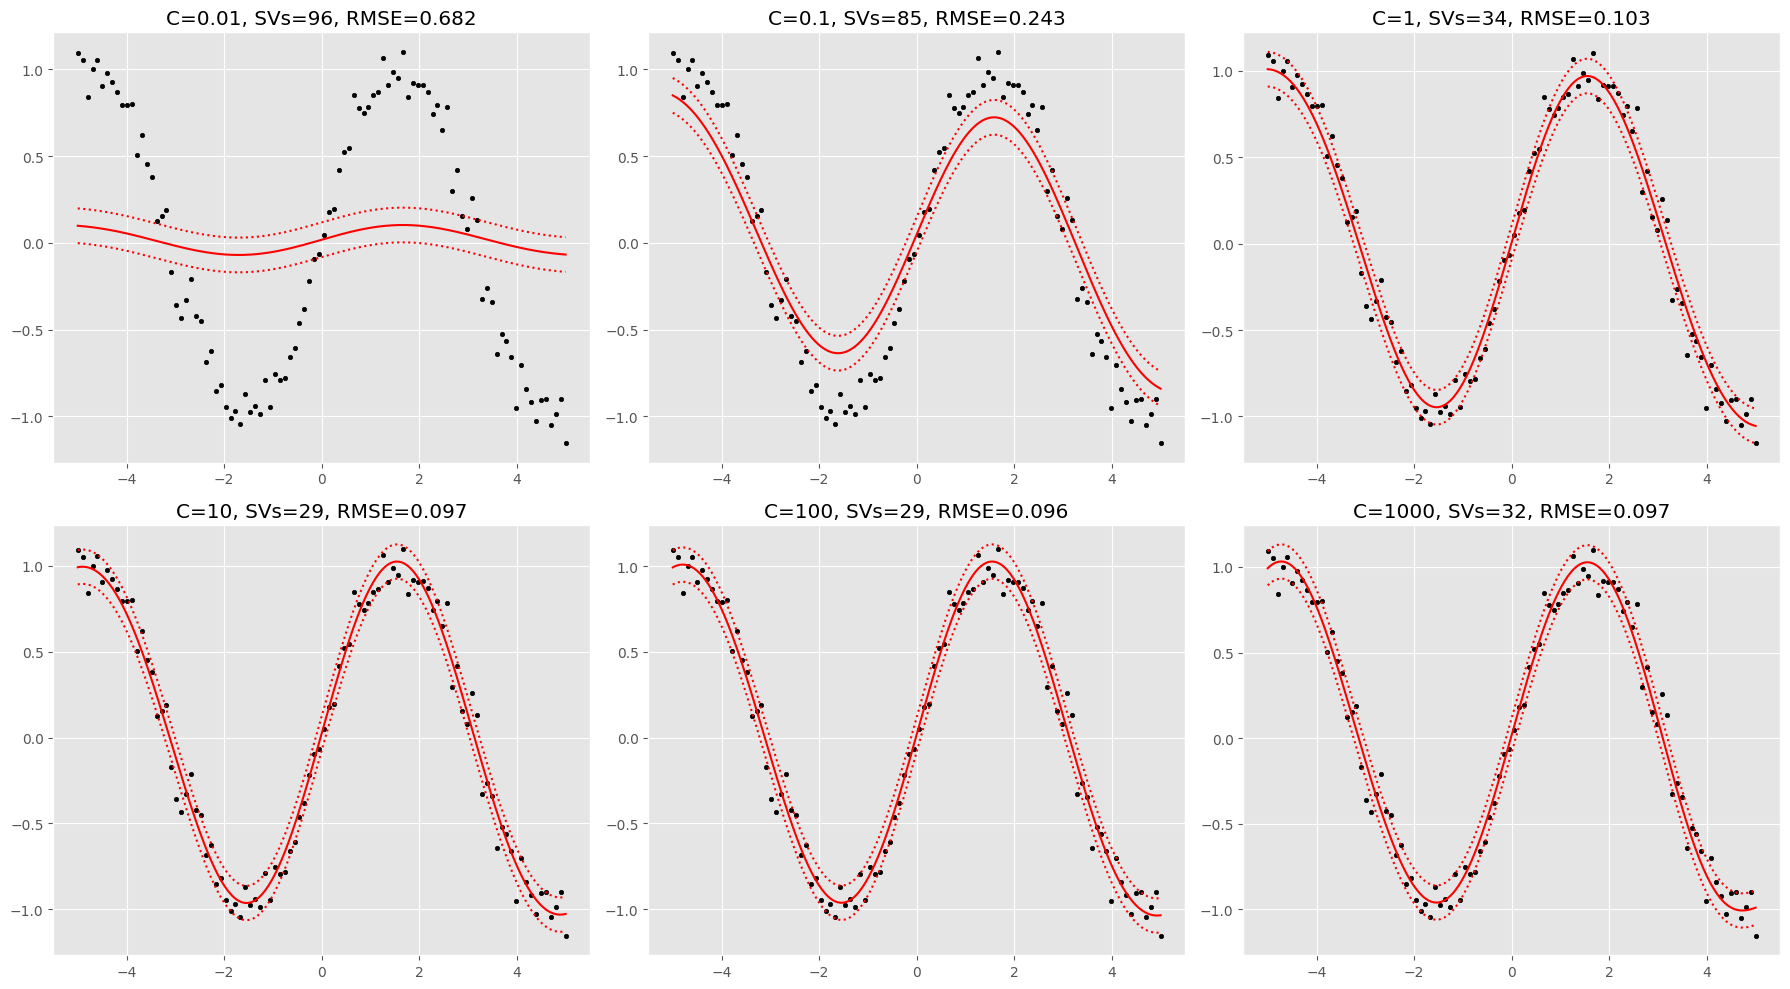

In [37]:
#Exercise 2: varying C
Cs = [0.01, 0.1, 1, 10, 100, 1000]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, C in zip(axes.ravel(), Cs):
    m = SVR(kernel='rbf', C=C, epsilon=0.1).fit(X, y)
    y_hat = m.predict(x_range)
    ax.scatter(X, y, s=10, color='black')
    ax.plot(x_range, y_hat, 'r')
    ax.plot(x_range, y_hat + 0.1, 'r:', x_range, y_hat - 0.1, 'r:')
    rmse = math.sqrt(metrics.mean_squared_error(y, m.predict(X)))
    ax.set_title(f"C={C}, SVs={len(m.support_)}, RMSE={rmse:.3f}")
plt.tight_layout()
plt.show()

Observations:

C is the penalty on points that fall outside the tube. It trades off a flat (simple) function against fitting the training points.
With a small C (0.01), errors cost very little, so the model prefers a nearly flat function and underfits (RMSE 0.682). Almost every point lies outside the tube and becomes a support vector.
As C grows to 1 and 10, the curve bends to follow the sine shape and RMSE falls to about 0.1, the noise level.
Beyond C = 10, the results barely change on this data, because almost all points already fit inside the tube. With noisier data or a smaller epsilon, a very large C would make the curve chase individual outliers and overfit.
C plays the role of an inverse regularization strength: a small C means strong regularization and a large C means weak regularization.


Breast cancer: raw accuracy=0.947, scaled accuracy=0.982, macro F1=0.981
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        42
      benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

  C=0.001: accuracy=0.877
  C=0.01: accuracy=0.956
  C=1: accuracy=0.982
  C=100: accuracy=0.965


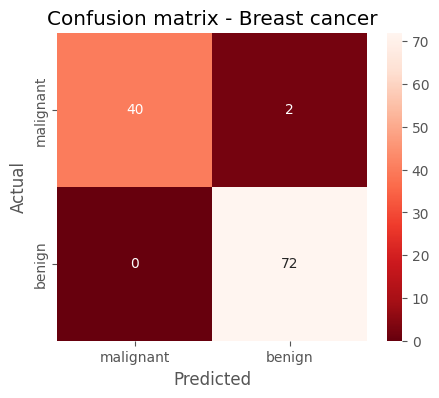


Iris: raw accuracy=1.000, scaled accuracy=0.967, macro F1=0.967
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

  C=0.001: accuracy=0.867
  C=0.01: accuracy=0.800
  C=1: accuracy=0.967
  C=100: accuracy=1.000


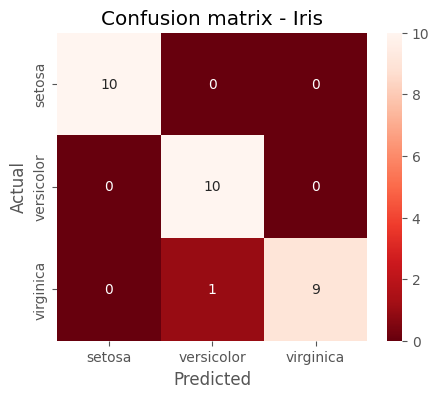


Wine: raw accuracy=0.972, scaled accuracy=1.000, macro F1=1.000
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

  C=0.001: accuracy=0.778
  C=0.01: accuracy=0.972
  C=1: accuracy=1.000
  C=100: accuracy=1.000


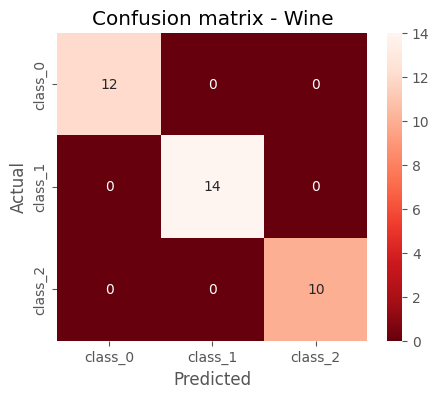

In [38]:
#Logistic regression
#Exercise 1: logistic regression on other datasets
from sklearn.datasets import load_breast_cancer, load_iris, load_wine
from sklearn.preprocessing import StandardScaler

datasets = {"Breast cancer": load_breast_cancer(), "Iris": load_iris(), "Wine": load_wine()}

for name, d in datasets.items():
    Xtr, Xte, ytr, yte = train_test_split(d.data, d.target, test_size=0.2,
                                          random_state=0, stratify=d.target)
    # without scaling
    raw_acc = LogisticRegression(max_iter=100).fit(Xtr, ytr).score(Xte, yte)

    # with scaling
    sc = StandardScaler().fit(Xtr)
    Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
    clf = LogisticRegression(max_iter=1000).fit(Xtr_s, ytr)
    y_pred = clf.predict(Xte_s)

    print(f"\n{name}: raw accuracy={raw_acc:.3f}, scaled accuracy={metrics.accuracy_score(yte, y_pred):.3f}, "
          f"macro F1={metrics.f1_score(yte, y_pred, average='macro'):.3f}")
    print(metrics.classification_report(yte, y_pred, target_names=[str(t) for t in d.target_names]))

    for C in [0.001, 0.01, 1, 100]:
        acc = LogisticRegression(C=C, max_iter=1000).fit(Xtr_s, ytr).score(Xte_s, yte)
        print(f"  C={C}: accuracy={acc:.3f}")

    cm = metrics.confusion_matrix(yte, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap='Reds_r',
                xticklabels=d.target_names, yticklabels=d.target_names)
    plt.title(f"Confusion matrix - {name}")
    plt.ylabel("Actual"); plt.xlabel("Predicted")
    plt.show()

Observations:

Logistic regression does well on all three datasets (above 95% accuracy), so the classes are close to linearly separable in the original feature space. The digits dataset in the notebook gave a similar result.
Feature scaling matters. Breast cancer and wine have features on very different scales (for example, area in the hundreds against smoothness around 0.1). Without scaling, the solver does not converge within 100 iterations, and accuracy is lower (0.947 against 0.982 for breast cancer). Iris features are already on similar scales, so scaling makes no real difference there. The 1.000 against 0.967 gap is one test sample out of 30.
In sklearn, C is the inverse of regularization strength. A very small C (0.001) shrinks the weights too much, and accuracy drops to 78-88%. C between 1 and 100 works best. For breast cancer, C = 100 is slightly worse than C = 1 (0.965 against 0.982), which points to mild overfitting with too little regularization.
On the multi-class datasets (iris, wine), sklearn fits a multinomial (softmax) logistic regression. The confusion matrix for iris shows that the errors fall between versicolor and virginica, the two classes that overlap. Setosa is always classified correctly.
On breast cancer, accuracy alone is not enough. A missed malignant tumour (false negative) is more costly than a false alarm, so recall for the malignant class from the classification report should be checked as well.